# 🏦 Bank mijozlarining ketishini bashorat qilish (Bank Customer Churn Prediction)
### Bank mijozlarining qarzni qaytarish prognozi — Mohirdev Kaggle musobaqasi

**Vazifa:** Bank mijozlarining ketishini bashorat qilish — Machine Learning (mashinani oʻqitish) yordamida bank sohasida mijozlar sonini prognoz qilish.


In [108]:
!pip install -q pandas numpy scikit-learn lightgbm xgboost matplotlib seaborn

In [92]:
!pip install -q catboost

In [109]:
import os
import glob
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

print("Libraries loaded")

Libraries loaded


In [110]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [112]:
SEED = 42
N_FOLDS = 5
TARGET = "Exited"
OUTPUT_PATH = "submission.csv"


def find_file(name, extra_dirs=()):
    search_dirs = [".", "./data", *extra_dirs, *glob.glob("/kaggle/input/*"), *glob.glob("/kaggle/input/*/*")]
    for d in search_dirs:
        path = os.path.join(d, name)
        if os.path.exists(path):
            return path
    return None


TRAIN_PATH = find_file("train.csv")
TEST_PATH = find_file("test.csv")
SUB_PATH = find_file("sample_submission.csv")
ORIGINAL_PATH = find_file("Churn_Modelling.csv")

if TRAIN_PATH is None or TEST_PATH is None or SUB_PATH is None:
    raise FileNotFoundError(
        "Could not find train.csv / test.csv / sample_submission.csv. "
        "Place them next to this notebook (or in ./data) and run again."
    )

USE_ORIGINAL = ORIGINAL_PATH is not None

print(f"train.csv            -> {TRAIN_PATH}")
print(f"test.csv             -> {TEST_PATH}")
print(f"sample_submission    -> {SUB_PATH}")
print(f"original dataset     -> {ORIGINAL_PATH or 'not found (optional, skipping)'}")

train.csv            -> ./train.csv
test.csv             -> ./test.csv
sample_submission    -> ./sample_submission.csv
original dataset     -> not found (optional, skipping)


## 2. Ma'lumotlarni yuklash

In [113]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sample_sub = pd.read_csv(SUB_PATH)

print(f"Train: {train.shape[0]:,} rows × {train.shape[1]} columns")
print(f"Test:  {test.shape[0]:,} rows × {test.shape[1]} columns")
print(f"Sample submission: {sample_sub.shape[0]:,} rows, columns = {list(sample_sub.columns)}")
train.head()

Train: 15,000 rows × 14 columns
Test:  10,000 rows × 13 columns
Sample submission: 10,000 rows, columns = ['id', 'Exited']


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15702656.0,Nwora,567.0,France,Male,33.0,9.0,0.0,2.0,1.0,0.0,156792.89,0.0
1,1,15647965.0,Yevdokimova,628.0,France,Female,38.0,3.0,0.0,1.0,1.0,1.0,51987.99,1.0
2,2,15798834.0,Ch'iu,635.0,France,Female,29.0,3.0,0.0,2.0,1.0,1.0,113079.19,0.0
3,3,15672056.0,Hsia,681.0,France,Male,28.0,6.0,0.0,2.0,1.0,0.0,14081.64,0.0
4,4,15759537.0,Okwudilichukwu,587.0,France,Female,27.0,5.0,0.0,2.0,1.0,0.0,158958.90,0.0


In [114]:
overview = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "missing_train": train.isna().sum(),
    "missing_test": test.isna().sum().reindex(train.columns),
    "n_unique": train.nunique(),
    "example": train.iloc[0],
})
overview

,dtype,missing_train,missing_test,n_unique,example
id,int64,0,0.0,15000,0
CustomerId,float64,0,0.0,6306,15702656.0
Surname,object,0,0.0,758,Nwora
CreditScore,float64,0,0.0,378,567.0
Geography,object,0,0.0,3,France
Gender,object,0,0.0,2,Male
Age,float64,0,0.0,55,33.0
Tenure,float64,0,0.0,11,9.0
Balance,float64,0,0.0,3328,0.0
NumOfProducts,float64,0,0.0,5,2.0


Ikkala faylda ham bo'sh yoki yetishmayotgan qiymatlar yo'q. `id` va `CustomerId` bu shunchaki identifikatorlar shuning uchun ularni modellarga bermaymiz.

## 3. Ma'lumotlarning tadqiqiy tahlili (EDA)
### 3.1 Maqsadli o'zgaruvchi (target) balansi

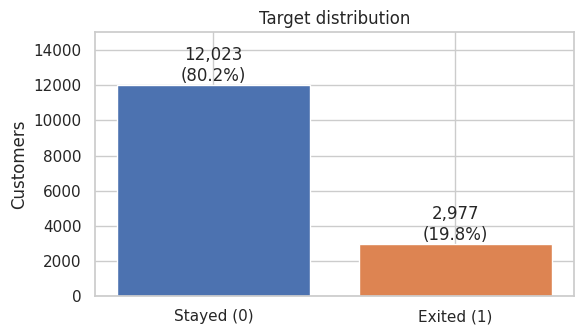

Churn rate: 19.85% → classes are imbalanced (~1 in 5 leaves).
We use STRATIFIED folds so every fold keeps this same ratio.


In [115]:
churn_rate = train[TARGET].mean()
counts = train[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(["Stayed (0)", "Exited (1)"], counts.values, color=["#4C72B0", "#DD8452"])
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,}\n({v / len(train):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("Target distribution")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()

print(f"Churn rate: {churn_rate:.2%} → classes are imbalanced (~1 in 5 leaves).")
print("We use STRATIFIED folds so every fold keeps this same ratio.")

### 3.2 Sonli belgilar

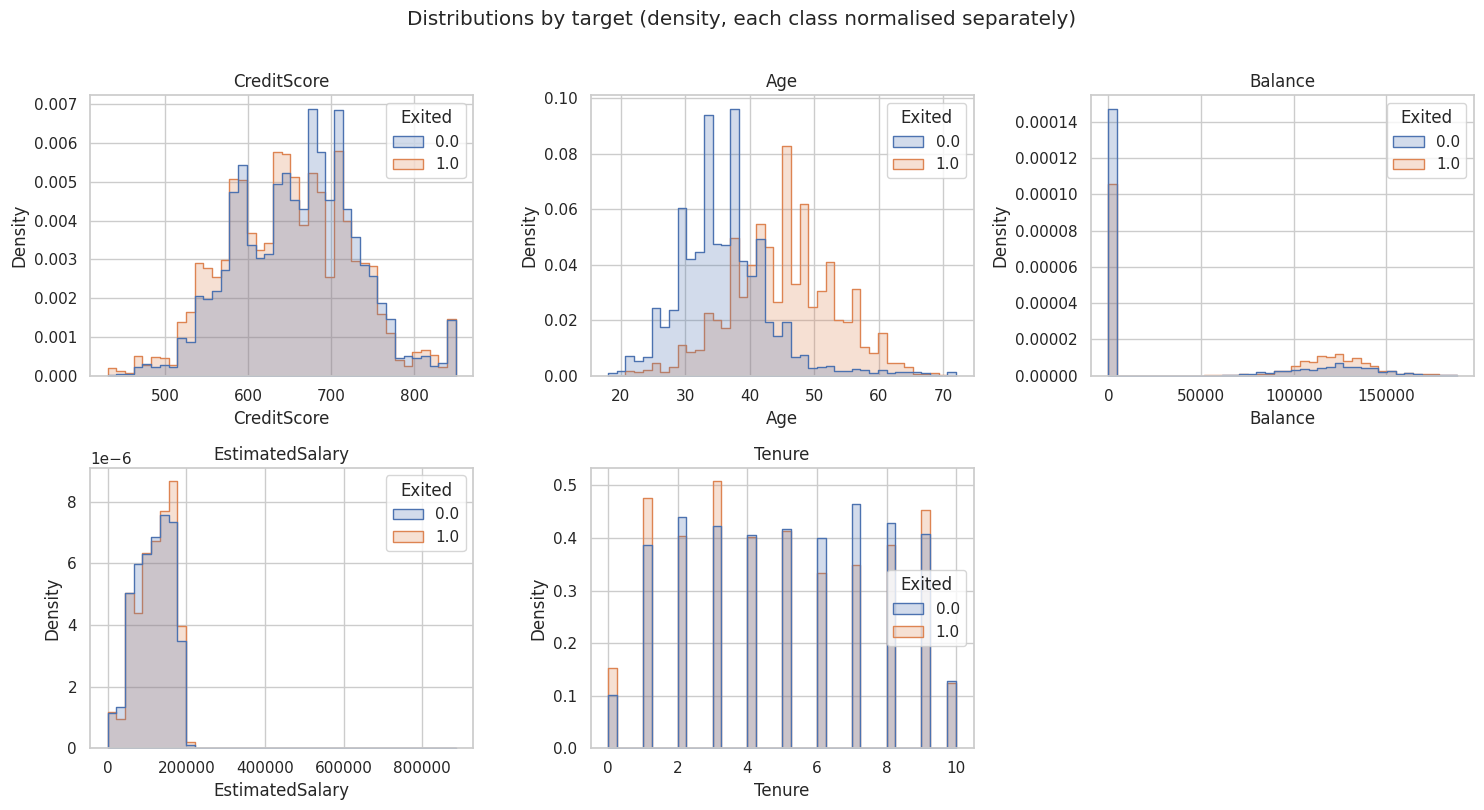

In [116]:
num_cols_eda = ["CreditScore", "Age", "Balance", "EstimatedSalary", "Tenure"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols_eda):
    sns.histplot(data=train, x=col, hue=TARGET, bins=40, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.suptitle("Distributions by target (density, each class normalised separately)", y=1.01)
plt.tight_layout()
plt.show()

### 3.3 Kategoriyalar bo'yicha churn rate

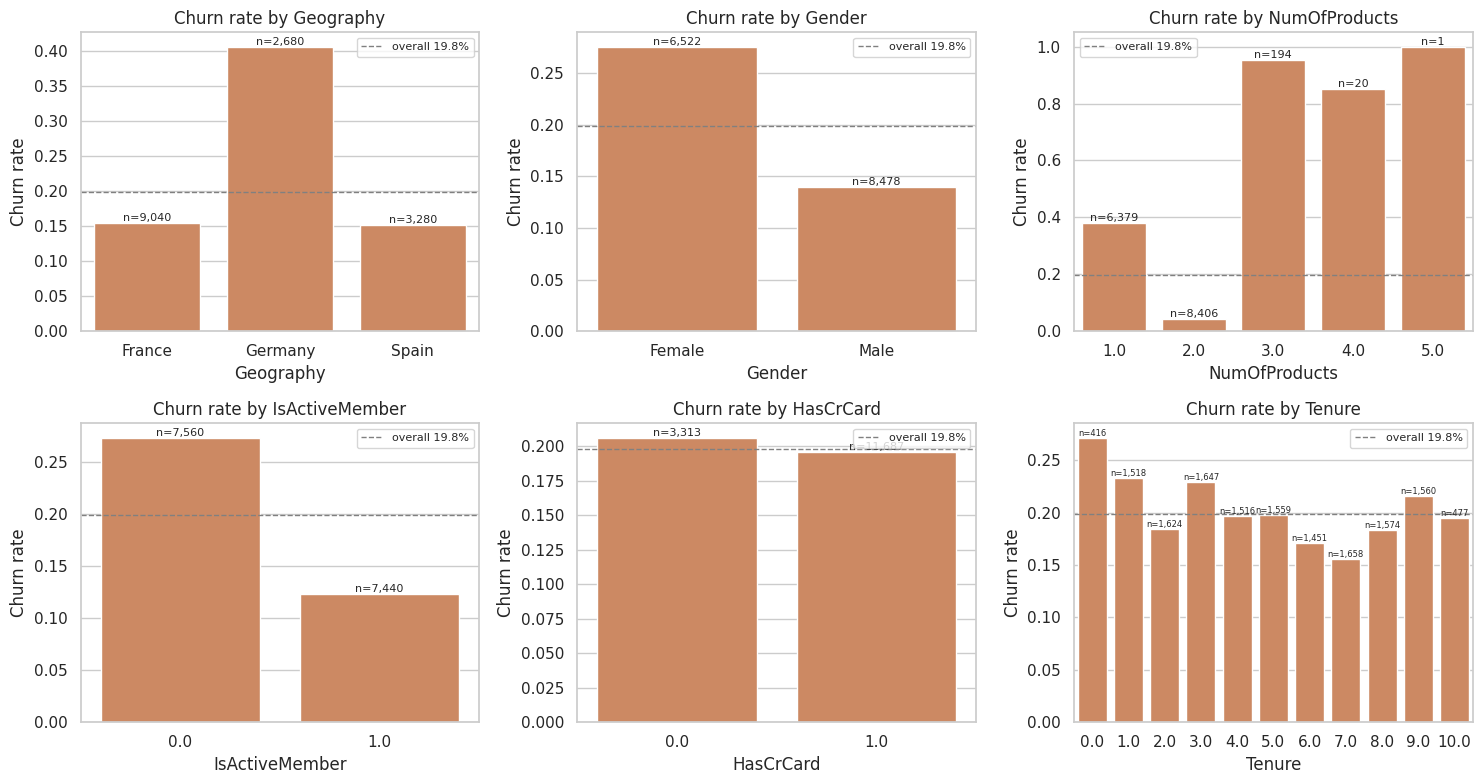

In [117]:
cat_cols_eda = ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard", "Tenure"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cat_cols_eda):
    stats = train.groupby(col)[TARGET].agg(["mean", "size"]).reset_index()
    sns.barplot(data=stats, x=col, y="mean", ax=ax, color="#DD8452")
    ax.axhline(churn_rate, ls="--", color="grey", lw=1, label=f"overall {churn_rate:.1%}")
    for p, n in zip(ax.patches, stats["size"]):
        ax.annotate(f"n={n:,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8 if len(stats) <= 5 else 6)
    ax.set_ylabel("Churn rate")
    ax.set_title(f"Churn rate by {col}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [118]:
age_groups = pd.cut(train["Age"], bins=[0, 30, 40, 50, 60, 100], labels=["≤30", "31–40", "41–50", "51–60", "60+"])
summary = pd.DataFrame({
    "churn_rate": train.groupby(age_groups)[TARGET].mean(),
    "customers": train.groupby(age_groups).size(),
})
summary.index.name = "Age group"
summary

,churn_rate,customers
Age group,,
≤30,0.041101,2506
31–40,0.097431,8057
41–50,0.405819,3265
51–60,0.720000,950
60+,0.360360,222


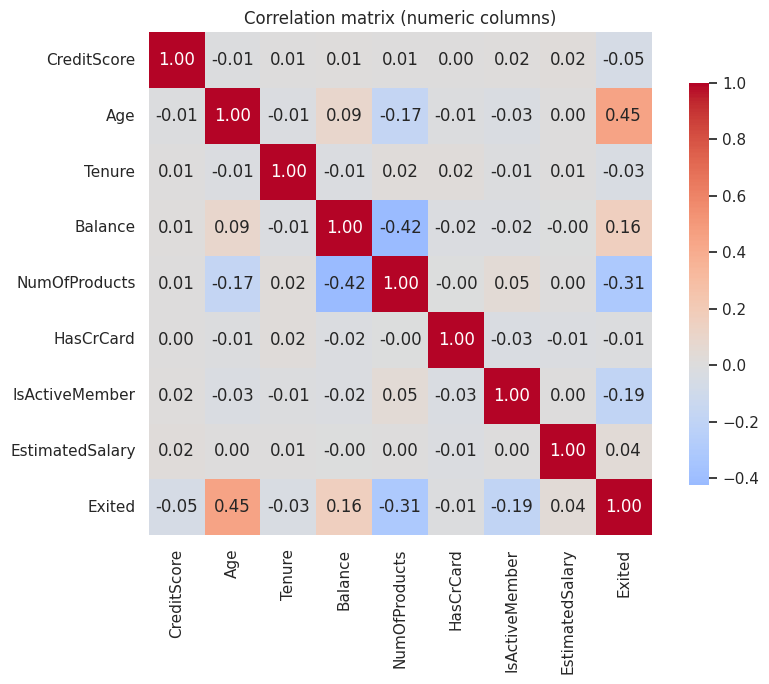

In [119]:
corr = train.drop(columns=["id", "CustomerId", "Surname", "Geography", "Gender"]).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix (numeric columns)")
plt.tight_layout()
plt.show()

**EDA bo'yicha xulosalar**
- **Age (yosh)** — eng kuchli yakka signal: ketish darajasi ~4% (≤30 yosh) dan ~72% (51–60 yosh) gacha oshadi. Bog'liqlik *nochiziqli* (60 yoshdan keyin yana pasayadi) → daraxtga asoslangan modellar buni chiziqli modelga qaraganda yaxshiroq aniqlaydi.
- **NumOfProducts (mahsulotlar soni)** juda nochiziqli: **2** ta mahsuloti bor mijozlar deyarli ketmaydi (~4%), **3–4** ta mahsuloti borlar esa deyarli har doim ketadi (85–95%).
- **Germaniya**dagi mijozlar Fransiya/Ispaniyaga qaraganda ~2.6 marta ko'proq ketadi; **ayollar** va **faol bo'lmagan** a'zolar ham ko'proq ketadi.
- **Balansi noldan katta** bo'lgan mijozlar ko'proq ketadi (~29% ga qarshi ~15%).
- `HasCrCard`, `Tenure`, `EstimatedSalary` o'z-o'zidan juda kam signal beradi.

## 4. Ma'lumotlarni tozalash
Sintetik tarzda yaratilgan, orasiga bir nechta bo'lishi mumkin bo'lmagan qiymatlar kirib qolgan ma'lumotlarni topamiz:

In [120]:
checks = {
    "EstimatedSalary > 200,000":   (train["EstimatedSalary"] > 200_000).sum(),
    "NumOfProducts > 4 (train)":   (train["NumOfProducts"] > 4).sum(),
    "NumOfProducts > 4 (test)":    (test["NumOfProducts"] > 4).sum(),
    "Max salary train / test":     f"{train['EstimatedSalary'].max():,.0f} / {test['EstimatedSalary'].max():,.0f}",
}
pd.Series(checks, name="value").to_frame()

,value
"EstimatedSalary > 200,000",1
NumOfProducts > 4 (train),1
NumOfProducts > 4 (test),2
Max salary train / test,"885,121 / 199,992"


In [122]:
INT_COLS = ["CreditScore", "Age", "Tenure", "NumOfProducts", "HasCrCard", "IsActiveMember"]


def clean(df):
    df = df.copy()
    df["EstimatedSalary"] = df["EstimatedSalary"].clip(upper=200_000)
    df["NumOfProducts"] = df["NumOfProducts"].clip(upper=4)
    df[INT_COLS] = df[INT_COLS].round().astype(int)
    return df


train_clean = clean(train)
test_clean = clean(test)
print("Cleaning done ")
print("NumOfProducts values now:", sorted(train_clean["NumOfProducts"].unique().tolist()))

Cleaning done 
NumOfProducts values now: [1, 2, 3, 4]


## 5. Belgilarni (features) tayyorlash
- **Sonli belgilar** — o'z holicha ishlatiladi (daraxt modellari masshtablashni talab qilmaydi).
- **`Geography`, `Gender`** — kategorik belgilar, barcha modellarda ishlatiladi.
- **`Surname`** — unikal qiymatlari juda ko'p (high-cardinality) bo'lgan matnli kategoriya (~750 ta unikal qiymat). CatBoost uni o'zining ichki *ordered target statistics* usuli bilan xavfsiz kodlaydi, bu esa CV natijasini kichik, ammo barqaror yaxshiladi. Boshqa modellar bu belgini ishlatmaydi (aks holda overfitting — o'quv ma'lumotlariga haddan tashqari moslashib qolish yuz beradi).

> Qo'shimcha yaratilgan belgilar (yosh × faollik, balans/maosh nisbati, yosh guruhlari va h.k.) sinab ko'rildi, lekin cross-validation AUC natijasini **yaxshilamadi** — gradient boosting bu o'zaro bog'liqliklarni o'zi topadi — shuning uchun belgilar to'plamini sodda qoldiramiz.

In [124]:
NUM_FEATURES = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                "HasCrCard", "IsActiveMember", "EstimatedSalary"]
CAT_FEATURES = ["Geography", "Gender"]
HIGH_CARD_FEATURES = ["Surname"]

BASE_FEATURES = NUM_FEATURES + CAT_FEATURES
CATBOOST_FEATURES = BASE_FEATURES + HIGH_CARD_FEATURES

if USE_ORIGINAL:
    original = clean(pd.read_csv(ORIGINAL_PATH).dropna(subset=CATBOOST_FEATURES + [TARGET]))
    print(f"Original dataset added: {len(original):,} extra training rows")
else:
    original = pd.DataFrame(columns=CATBOOST_FEATURES + [TARGET])

for col in CAT_FEATURES + HIGH_CARD_FEATURES:
    all_values = pd.concat([train_clean[col], test_clean[col], original[col]]).astype(str).unique()
    for df in (train_clean, test_clean, original):
        df[col] = pd.Categorical(df[col].astype(str), categories=sorted(all_values))

X = train_clean[CATBOOST_FEATURES].reset_index(drop=True)
y = train_clean[TARGET].astype(int).values
X_test = test_clean[CATBOOST_FEATURES].reset_index(drop=True)
X_orig = original[CATBOOST_FEATURES].reset_index(drop=True)
y_orig = original[TARGET].astype(int).values

print(f"X: {X.shape}, X_test: {X_test.shape}, X_orig: {X_orig.shape}")
X.head()

X: (15000, 11), X_test: (10000, 11), X_orig: (0, 11)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography,Gender,Surname
0,567,33,9,0.0,2,1,0,156792.89,France,Male,Nwora
1,628,38,3,0.0,1,1,1,51987.99,France,Female,Yevdokimova
2,635,29,3,0.0,2,1,1,113079.19,France,Female,Ch'iu
3,681,28,6,0.0,2,1,0,14081.64,France,Male,Hsia
4,587,27,5,0.0,2,1,0,158958.90,France,Female,Okwudilichukwu


## 6. Cross-validation tizimi
Biz **Stratified 5-fold CV**: ma'lumotlar 5 qismga bo'linadi; har bir model 5 marta o'qitiladi va har safar o'zi ko'rmagan qismda tekshiriladi.

Bu esa bizga quyidagilarni beradi:
- Har bir o'quv qatori uchun **Out-of-fold (OOF) bashoratlar** → AUC ning xolis bahosi va blending uchun ma'lumot.
- **Test bashoratlari** = 5 ta fold modelining o'rtachasi → bitta modelga qaraganda barqarorroq.

In [125]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
results = {}


def run_cv(name, fit_predict, features):
    oof = np.zeros(len(X))
    test_pred = np.zeros(len(X_test))
    fold_scores, models = [], []
    start = time.time()

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
        X_tr, y_tr = X.loc[tr_idx, features], y[tr_idx]
        X_va, y_va = X.loc[va_idx, features], y[va_idx]

        if USE_ORIGINAL:
            X_tr = pd.concat([X_tr, X_orig[features]], ignore_index=True)
            y_tr = np.concatenate([y_tr, y_orig])

        model, va_pred, te_pred = fit_predict(X_tr, y_tr, X_va, y_va, X_test[features])
        oof[va_idx] = va_pred
        test_pred += te_pred / N_FOLDS
        fold_scores.append(roc_auc_score(y_va, va_pred))
        models.append(model)
        print(f"  Fold {fold}: AUC = {fold_scores[-1]:.5f}")

    cv_auc = roc_auc_score(y, oof)
    elapsed = time.time() - start
    print(f"▶ {name}: CV AUC = {cv_auc:.5f} (± {np.std(fold_scores):.5f})  |  {elapsed:.0f}s")
    results[name] = dict(oof=oof, test=test_pred, auc=cv_auc, std=np.std(fold_scores),
                         time=elapsed, models=models, features=features)
    return oof, test_pred

## 7. Modellar
### 7.1 Bazaviy model — Logistic Regression


In [126]:
def fit_logreg(X_tr, y_tr, X_va, y_va, X_te):
    preprocess = ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ])
    model = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
    model.fit(X_tr, y_tr)
    return model, model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]


_ = run_cv("Logistic Regression", fit_logreg, BASE_FEATURES)

  Fold 1: AUC = 0.89200
  Fold 2: AUC = 0.87994
  Fold 3: AUC = 0.88355
  Fold 4: AUC = 0.87669
  Fold 5: AUC = 0.88238
▶ Logistic Regression: CV AUC = 0.88282 (± 0.00511)  |  0s


### 7.2 LightGBM
Kichik learning rate va **early stopping** dan foydalanamiz: validationdagi AUC 200 raund davomida yaxshilanmasa, o'qitish avtomatik to'xtaydi.

In [127]:
LGB_PARAMS = dict(
    n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=40,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=2.0,
    random_state=SEED, verbose=-1,
)


def fit_lgbm(X_tr, y_tr, X_va, y_va, X_te):
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="auc",
              callbacks=[lgb.early_stopping(200, verbose=False)])
    return model, model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]


_ = run_cv("LightGBM", fit_lgbm, BASE_FEATURES)

  Fold 1: AUC = 0.93815
  Fold 2: AUC = 0.92987
  Fold 3: AUC = 0.93250
  Fold 4: AUC = 0.93233
  Fold 5: AUC = 0.93527
▶ LightGBM: CV AUC = 0.93322 (± 0.00284)  |  10s


### 7.3 XGBoost

In [128]:
XGB_PARAMS = dict(
    n_estimators=3000, learning_rate=0.02, max_depth=4, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.6, reg_lambda=2.0,
    tree_method="hist", enable_categorical=True,
    eval_metric="auc", early_stopping_rounds=200, random_state=SEED,
)


def fit_xgb(X_tr, y_tr, X_va, y_va, X_te):
    model = xgb.XGBClassifier(**XGB_PARAMS)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return model, model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]


_ = run_cv("XGBoost", fit_xgb, BASE_FEATURES)

  Fold 1: AUC = 0.93855
  Fold 2: AUC = 0.92972
  Fold 3: AUC = 0.93251
  Fold 4: AUC = 0.93212
  Fold 5: AUC = 0.93524
▶ XGBoost: CV AUC = 0.93326 (± 0.00302)  |  7s


### 7.4 CatBoost (+ Surname)
CatBoost kategorik belgilar bilan bevosita ishlay oladi — jumladan, unikal qiymatlari ko'p bo'lgan `Surname` bilan ham — qo'lda kodlash shart emas. Bu eng sekin model (~1 daqiqa), lekin bu masalada odatda eng kuchlisi.

In [129]:
CB_PARAMS = dict(
    iterations=3000, learning_rate=0.03, depth=6, l2_leaf_reg=5,
    eval_metric="AUC", early_stopping_rounds=200, random_seed=SEED, verbose=0,
)


def fit_catboost(X_tr, y_tr, X_va, y_va, X_te):
    cat_cols = [c for c in X_tr.columns if c in CAT_FEATURES + HIGH_CARD_FEATURES]
    to_str = lambda df: df.astype({c: str for c in cat_cols})
    model = CatBoostClassifier(**CB_PARAMS)
    model.fit(to_str(X_tr), y_tr, cat_features=cat_cols, eval_set=(to_str(X_va), y_va))
    return model, model.predict_proba(to_str(X_va))[:, 1], model.predict_proba(to_str(X_te))[:, 1]


_ = run_cv("CatBoost", fit_catboost, CATBOOST_FEATURES)

  Fold 1: AUC = 0.93900
  Fold 2: AUC = 0.93064
  Fold 3: AUC = 0.93516
  Fold 4: AUC = 0.93392
  Fold 5: AUC = 0.93725
▶ CatBoost: CV AUC = 0.93504 (± 0.00287)  |  62s


## 8. Modellarni taqqoslash

In [130]:
leaderboard = (
    pd.DataFrame({name: {"CV AUC": r["auc"], "Fold std": r["std"], "Time (s)": r["time"]}
                  for name, r in results.items()})
    .T.sort_values("CV AUC", ascending=False)
)
leaderboard.round({"CV AUC": 5, "Fold std": 5, "Time (s)": 1})

,CV AUC,Fold std,Time (s)
CatBoost,0.93504,0.00287,62.0
XGBoost,0.93326,0.00302,6.8
LightGBM,0.93322,0.00284,10.0
Logistic Regression,0.88282,0.00511,0.4


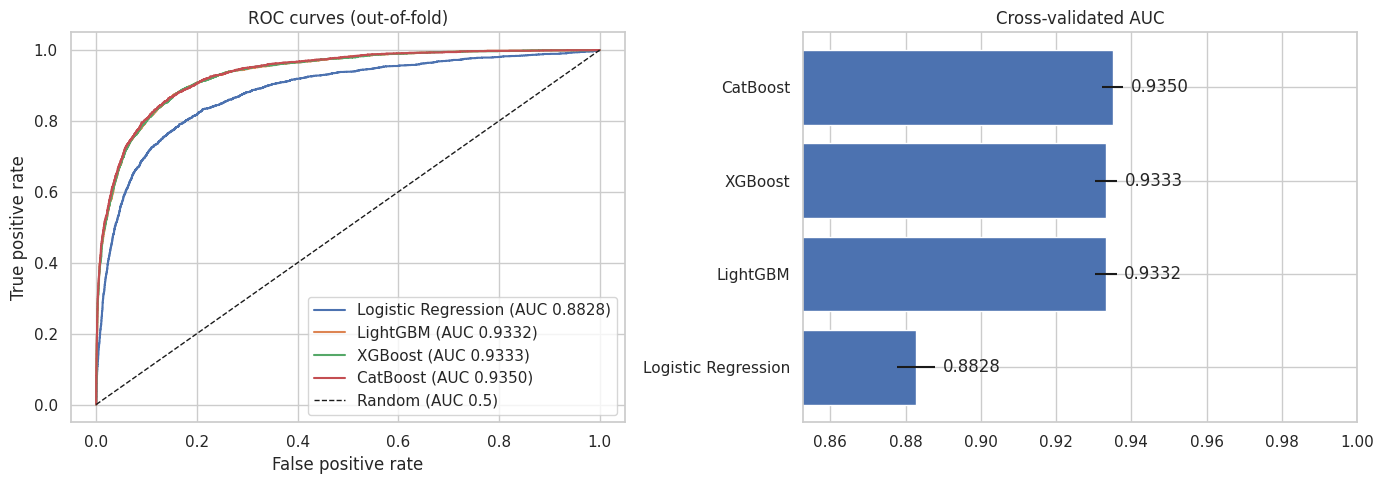

In [131]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, r in results.items():
    fpr, tpr, _ = roc_curve(y, r["oof"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {r['auc']:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC 0.5)")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (out-of-fold)")
axes[0].legend(loc="lower right")

lb = leaderboard.sort_values("CV AUC")
axes[1].barh(lb.index, lb["CV AUC"], xerr=lb["Fold std"], color="#4C72B0")
for i, (v, sd) in enumerate(zip(lb["CV AUC"], lb["Fold std"])):
    axes[1].text(v + sd + 0.002, i, f"{v:.4f}", va="center")
axes[1].set_xlim(lb["CV AUC"].min() - 0.03, 1.0)
axes[1].set_title("Cross-validated AUC")

plt.tight_layout()
plt.show()

## 9. Blending
Uchta boosting modeli uchun vaznlarni **OOF bashoratlar** asosida qidiramiz va eng yaxshi kombinatsiyani saqlab qolamiz. Agar bitta modelning o'zi eng yaxshi bo'lsa, qidiruv unga shunchaki 1.0 vazn beradi.

In [132]:
BLEND_MODELS = ["LightGBM", "XGBoost", "CatBoost"]
oof_matrix = np.column_stack([results[m]["oof"] for m in BLEND_MODELS])
test_matrix = np.column_stack([results[m]["test"] for m in BLEND_MODELS])

best_auc, best_w = 0.0, None
grid = np.round(np.arange(0, 1.0001, 0.05), 2)
for w1 in grid:
    for w2 in grid:
        w3 = round(1 - w1 - w2, 2)
        if w3 < 0:
            continue
        w = np.array([w1, w2, w3])
        auc = roc_auc_score(y, oof_matrix @ w)
        if auc > best_auc:
            best_auc, best_w = auc, w

best_single = leaderboard.index[0]
print("Best blend weights:", {m: float(w) for m, w in zip(BLEND_MODELS, best_w)})
print(f"Blend OOF AUC:        {best_auc:.5f}")
print(f"Best single model:    {best_single} ({results[best_single]['auc']:.5f})")
print(f"Gain from blending:   {best_auc - results[best_single]['auc']:+.5f}")

Best blend weights: {'LightGBM': 0.15, 'XGBoost': 0.0, 'CatBoost': 0.85}
Blend OOF AUC:        0.93512
Best single model:    CatBoost (0.93504)
Gain from blending:   +0.00008


In [133]:
final_oof = oof_matrix @ best_w
final_test = test_matrix @ best_w
pd.DataFrame(oof_matrix, columns=BLEND_MODELS).corr().round(3)

,LightGBM,XGBoost,CatBoost
LightGBM,1.000,0.998,0.990
XGBoost,0.998,1.000,0.991
CatBoost,0.990,0.991,1.000


## 10. Feature importance
CatBoost featurlari 5 ta fold modeli bo'yicha o'rtachalangan; taqqoslash uchun LightGBM gain ko'rsatkichi.

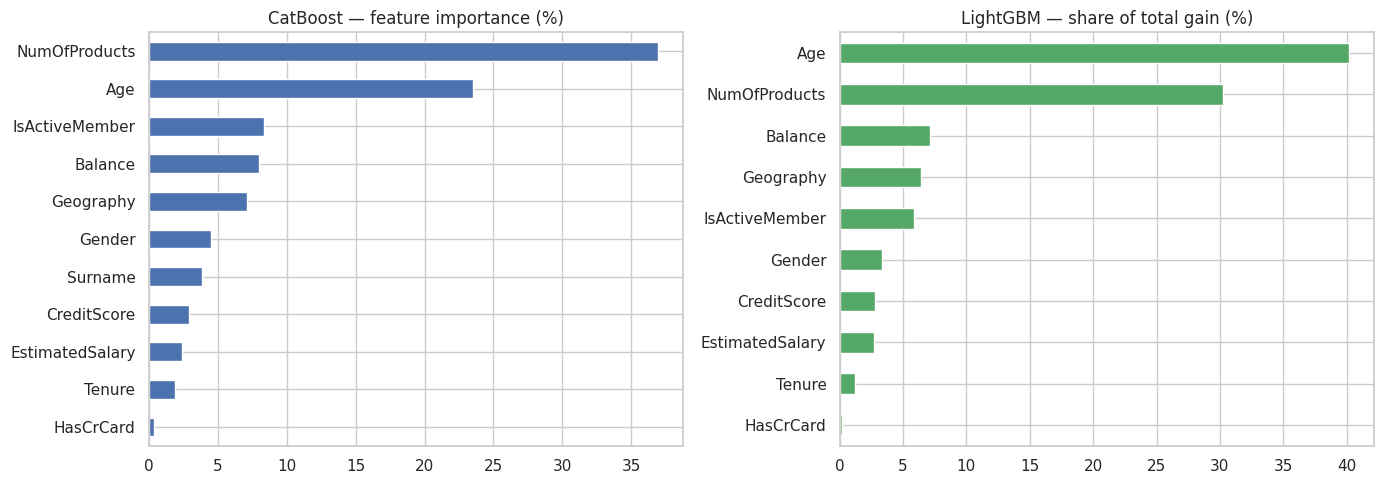

In [134]:
cb = results["CatBoost"]
cb_imp = pd.Series(np.mean([m.get_feature_importance() for m in cb["models"]], axis=0),
                   index=cb["features"]).sort_values()

lg = results["LightGBM"]
lgb_imp = pd.Series(np.mean([m.booster_.feature_importance("gain") for m in lg["models"]], axis=0),
                    index=lg["features"])
lgb_imp = (lgb_imp / lgb_imp.sum() * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cb_imp.plot.barh(ax=axes[0], color="#4C72B0", title="CatBoost — feature importance (%)")
lgb_imp.plot.barh(ax=axes[1], color="#55A868", title="LightGBM — share of total gain (%)")
plt.tight_layout()
plt.show()

Ikkala model ham EDA natijalariga mos keladi: bashoratlarga asosan **Age**, **NumOfProducts**, **IsActiveMember**, **Geography** va **Balance** ta'sir qiladi, `HasCrCard` esa deyarli ahamiyatga ega emas.

## 11. Submission faylini tayyorlash

In [135]:
pred = pd.DataFrame({"id": test["id"].values, TARGET: final_test})
submission = sample_sub[["id"]].merge(pred, on="id", how="left")

assert len(submission) == len(sample_sub), "Row count mismatch"
assert list(submission.columns) == ["id", TARGET], "Wrong columns"
assert submission[TARGET].notna().all(), "Missing predictions"
assert submission[TARGET].between(0, 1).all(), "Predictions must be probabilities in [0, 1]"
assert submission["id"].is_unique, "Duplicate ids"

submission.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {OUTPUT_PATH}: {submission.shape[0]:,} rows")
print(f"Mean predicted churn: {submission[TARGET].mean():.3f}  (train churn rate: {churn_rate:.3f})")
submission.head(10)

Saved submission.csv: 10,000 rows
Mean predicted churn: 0.200  (train churn rate: 0.198)


,id,Exited
0,15000,0.047997
1,15001,0.177808
2,15002,0.041171
3,15003,0.145206
4,15004,0.007435
5,15005,0.344962
6,15006,0.063386
7,15007,0.694022
8,15008,0.022722
9,15009,0.593750


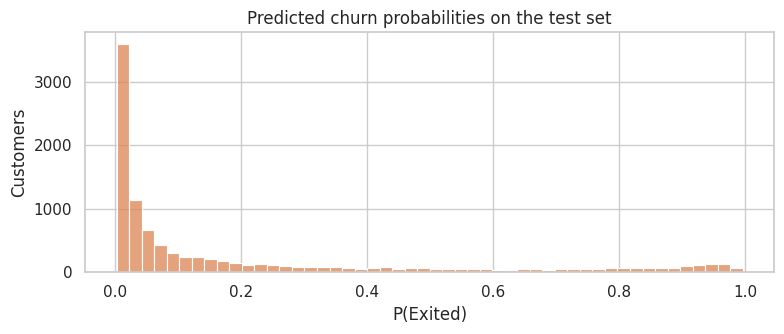

In [136]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(submission[TARGET], bins=50, ax=ax, color="#DD8452")
ax.set(title="Predicted churn probabilities on the test set", xlabel="P(Exited)", ylabel="Customers")
plt.tight_layout()
plt.show()

## 12. Xulosa
Bank mijozlarining ketish ehtimolini bashorat qilish uchun 4 ta model sinab ko'rdim va eng yaxshi natijani CatBoost ko'rsatdi (CV AUC ≈ 0.935). Mijozning ketishiga eng ko'p ta'sir qiladigan omillar — yoshi, mahsulotlar soni, faol a'zo ekani va yashash davlati. Misol uchun Germaniya. Yakuniy bashorat CatBoost va LightGBM modellarini birlashtirib oldim va `submission.csv` fayliga saqladim
.